## Klasifikacija recenzija mobilnih aplikacija pomocu biblioteka **spaCy** i sklearn (Bag of Words i Decision Trees)

Zadatak klasifikacije u ovom notebook-u je razvrstavanje recenzija korisnika mobilnih aplikacija u tri kategorije, koriscenjem **Bag of Words (BoW)** pristupa za predstavljanje teksta i algoritma stabla odlučivanja (Decision Tree – DT) za klasifikaciju:
* funkcionalni zahtevi,
* nefunkcionalni zahtevi,
* ostalo.

Skup podataka korišćen u ovom notebooku potiče iz  [Listening to the Crowd for the Release Planning of Mobile Apps](https://dl.acm.org/doi/abs/10.1109/TSE.2017.2759112).

In [1]:
# UCITAVANJE POTREBNIH BIBLIOTEKA

import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn import metrics

from sklearn.tree import DecisionTreeClassifier

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

import matplotlib.pyplot as plt
import seaborn as sb

import spacy

from IPython.display import display

from pathlib import Path

import pickle
import json

In [2]:
RAND_STATE = 1

#### UCITAVANJE PODATAKA

In [3]:
data = pd.read_csv(Path.cwd() / 'data' / 'mobile_apps_reviews.csv')

display(data.head(10))
data.info()

,id,app,version,rating,date,device,user,review,category
0,1,com.androtiyas.dragonvirtual,1.08,5,1387756426967,?,Alexis Gonzalez,cute!!!! the game is just to cute!!!! :3,OTHER
1,2,com.androtiyas.dragonvirtual,1.1,4,1390090741168,Galaxy Precedent,A Google User,? well its ok but not bad nor is it great,OTHER
2,3,com.androtiyas.dragonvirtual,?,1,1387746296815,Toshiba AT100,Reyna We,? have no idea how to feed dragon and boooorrr...,OTHER
3,4,com.androtiyas.dragonvirtual,1.06,2,1386518193950,?,mariah harris,when i play games it reboots about every third...,BUG
4,5,com.androtiyas.dragonvirtual,1.06,5,1386915595583,?,Wren Brown,love my dragon have fun! yahoooey! godbless,OTHER
5,6,com.androtiyas.dragonvirtual,1.11,5,1391710690867,?,Aribha Zahoor,hope this is a good game!!!! ?,OTHER
6,7,com.androtiyas.dragonvirtual,?,1,1396716326980,LG Optimus One,isaiah lawrence,sucks can't even play offline and everyone tak...,FEATURE
7,8,com.androtiyas.dragonvirtual,1.12,5,1397085800819,Samsung Galaxy Y,Charlotte Baynes,good that is so good,OTHER
8,9,com.androtiyas.dragonvirtual,1.1,5,1389305213694,HTC Wildfire S,A Google User,? realy good and fun,OTHER
9,10,com.androtiyas.dragonvirtual,1.11,5,1391957108087,?,Jennifer Bieber,999 this is the best,OTHER


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        3000 non-null   int64 
 1   app       3000 non-null   object
 2   version   3000 non-null   object
 3   rating    3000 non-null   int64 
 4   date      3000 non-null   int64 
 5   device    3000 non-null   object
 6   user      2991 non-null   object
 7   review    3000 non-null   object
 8   category  3000 non-null   object
dtypes: int64(3), object(6)
memory usage: 211.1+ KB


#### KREIRANJE IZLAZNE VARIJABLE

Koristicemo kolonu **_category_** za kreiranje izlazne varijable **_cls_**.

In [4]:
# pravimo novu kolonu cls sa 3 moguce vrednosti: OTHER, FUNCTIONAL (BUG, FEATURE) i NON-FUNCTIONAL (PERFORMANCE, USABILITY, ENERGY, SECURITY)

def category_to_cls(cat):
    if cat == 'OTHER': return cat
    return 'FUNCTIONAL' if cat in ['BUG', 'FEATURE'] else 'NON-FUNCTIONAL'


data['cls'] = data.category.apply(category_to_cls)

Provera balansiranosti dataseta

In [5]:
data.cls.value_counts(normalize=True)

# postoji class imbalance - klase nisu podjednako zastupljenje
# model moze da vara

cls
OTHER             0.501667
FUNCTIONAL        0.365667
NON-FUNCTIONAL    0.132667
Name: proportion, dtype: float64

Ako algoritam uopste ne analizira tekst recenzije, vec za svaku mogucu recenziju kaze da pripada klasi OTHER, on ce automatski imati tacnost (accuracy) od 50%.

Kreiranje varijable _review_len_

In [6]:
# duzina recenzija moze biti bitna - npr. duzi tekst uglavnom znaci da je u pitanju bag

data['review_len'] = data.review.apply(len)

In [8]:
# trenutni izgled dataseta:

data.head()

,id,app,version,rating,date,device,user,review,category,cls,review_len
0,1,com.androtiyas.dragonvirtual,1.08,5,1387756426967,?,Alexis Gonzalez,cute!!!! the game is just to cute!!!! :3,OTHER,OTHER,40
1,2,com.androtiyas.dragonvirtual,1.1,4,1390090741168,Galaxy Precedent,A Google User,? well its ok but not bad nor is it great,OTHER,OTHER,41
2,3,com.androtiyas.dragonvirtual,?,1,1387746296815,Toshiba AT100,Reyna We,? have no idea how to feed dragon and boooorrr...,OTHER,OTHER,60
3,4,com.androtiyas.dragonvirtual,1.06,2,1386518193950,?,mariah harris,when i play games it reboots about every third...,BUG,FUNCTIONAL,295
4,5,com.androtiyas.dragonvirtual,1.06,5,1386915595583,?,Wren Brown,love my dragon have fun! yahoooey! godbless,OTHER,OTHER,43


#### Provera znacajnosti prediktora

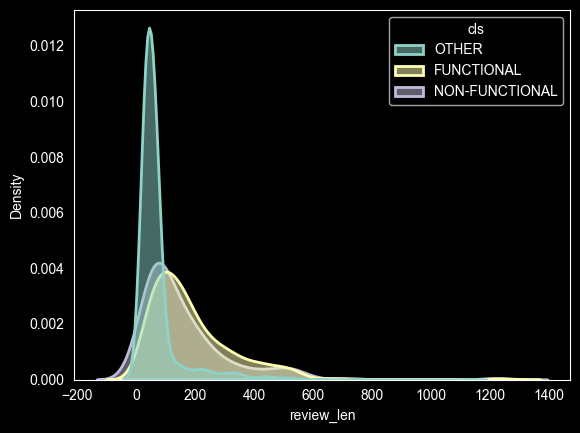

In [9]:
# review_len

plt.figure()
sb.kdeplot(data=data,
           x='review_len',
           hue='cls',
           fill=True,
           common_norm=False,
           # svaka kriva se normalizuje zasebno (povrsina = 1), pa se mogu porediti oblici raspodela bez obzira na to koliko je klasa velika
           alpha=0.5,
           linewidth=2)
plt.grid(False) # ja dodala jer je kod mene automatski grid
plt.show()

# izdvaja bar jednu klasu od ostale dve -> znacajan prediktor

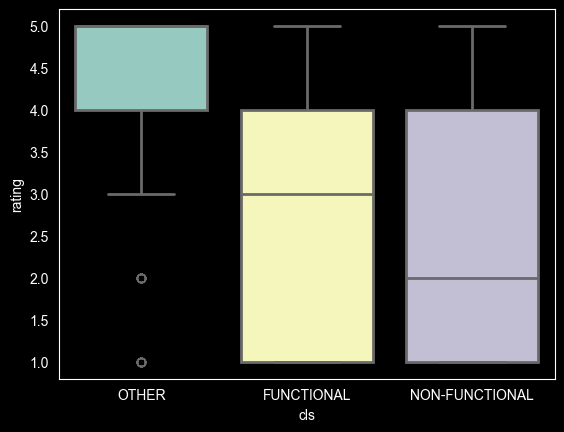

In [10]:
# rating

plt.figure()
# moze i ovde kdeplot
sb.boxplot(data=data,
           x='cls',
           y='rating',
           hue='cls', # kolona koja se koristi za bojenje - svaka ima svoju boju
           fill=True,
           linewidth=2,
           legend=False)
plt.grid(False)
plt.show()

# medijane po klasama se razlikuju (4,3,2) -> rating je takodje znacajan prediktor

In [11]:
# zadrzavamo tri prediktora (rating, review_len, review) i izlaznu varijablu (cls)

data_sub = data[['rating', 'review_len', 'review', 'cls']]

data_sub.head()

,rating,review_len,review,cls
0,5,40,cute!!!! the game is just to cute!!!! :3,OTHER
1,4,41,? well its ok but not bad nor is it great,OTHER
2,1,60,? have no idea how to feed dragon and boooorrr...,OTHER
3,2,295,when i play games it reboots about every third...,FUNCTIONAL
4,5,43,love my dragon have fun! yahoooey! godbless,OTHER


## PRETPROCESIRANJE TEKSTA (spacy)

In [12]:
# ucitavanje pipeline-a
nlp_pipe = spacy.load('en_core_web_sm')

In [13]:
def spacy_preprocessing(doc):
    # kreiranje tokena sa lingvistickim osobinama
    tokens = nlp_pipe(doc)
    # uklanjanje interpunkcija, praznina, brojeva i url
    tokens = [token for token in tokens
              if ((not token.is_punct) and (not token.is_space) and
                  (not token.like_num) and (not token.like_url))]
    # uklanjanje stop words, ali ostavljamo not - kljucno za analizu sentimenta (good != not good)
    tokens = [token for token in tokens
              if ((not token.is_stop) or (token.lemma_.lower() == 'not'))]

    # pretvaranje tokena u leme
    words = [token.lemma_ for token in tokens]

    # vracanje pretprocesuiranih reci
    return words

In [14]:
def create_count_vectorizer(ngrams=(1, 1), min_doc_freq=0.01, f_max=-1):
    vectoriser = CountVectorizer(
        tokenizer=spacy_preprocessing,  #umesto ugradjenog deljenja teksta, koristimo svoju funkciju
        token_pattern=None,  #kazemo da ne koristi regex
        ngram_range=ngrams,
        max_features=f_max if f_max > 0 else None,  # ogranicava recnik na n najcescih reci
        min_df=min_doc_freq  # rec ulazi u recnik samo ako se pojavljuje u najmanje 1% dokumenta
    )

    return vectoriser

# ngram_range=(1,1): n-gram je niz od n uzastopnih reci; (1,1) znaci samo pojedinacne reci (unigrami); (1,2) bi dodalo i parove ("not work"), cime se delimicno vraca kontekst, ali se recnik jako povecava

# max_features: ako je prosledjeni f_max veci od 0, zadrzace se samo top f_max najucestalijih reci
# posto je podrazumevano -1, uslov f_max > 0 nije ispunjen, pa se uzima None (recnik se ne ogranicava)

### Kreiranje i testiranje **pipeline**-a za klasifikaciju teksta

#### DELJENJE PODATAKA NA TRAIN I TEST SKUP

In [15]:
X = data_sub.drop(columns='cls')
y = data_sub.cls.values

In [16]:
# faktorizacija izlazne promenljive na 0 1 2 (Decision Tree moze da radi i sa tekstualnim klasama, ali se ovde klase kodiraju u numericki oblik radi lakseg rada

y_encodings, y_levels = pd.factorize(y) # kodiranje tekstualnih ili kategorickih podataka u numericke vrednosti (celobrojne nizove)

# y_encodings - stvarne numericke oznake klasa: [0, 1, 2, 0, 2]
# y_levels - informacije o tome koji broj predstavlja koju originalnu klasu: ['other','functional', 'non-functional']

display(y_levels)
pd.Series(y_encodings).value_counts()

array(['OTHER', 'FUNCTIONAL', 'NON-FUNCTIONAL'], dtype=object)

0    1505
1    1097
2     398
Name: count, dtype: int64

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y_encodings, # brojevi!!!
                                                    test_size=0.2,
                                                    random_state=RAND_STATE,
                                                    stratify=y_encodings
                                                    )

#### KREIRANJE VECTORISER-A I COLUMN TRANSFORMER-A

In [18]:
# pravimo instancu count vectoriser-a, koju smo gore definisali
count_vectorizer = create_count_vectorizer()

column_transformer = ColumnTransformer(
    [('word_counts', count_vectorizer, 'review')],
    remainder='passthrough' # sve preostale kolone, nenavedene
)

# [('ime_transformacije', transformator, 'kolona')]
# passthrough - sve kolone koje nismo posebno naveli samo prosledi dalje bez promene

#### KREIRANJE KLASIFIKATORA

In [19]:
# za klasifikaciju koristimo decision tree

classifier = DecisionTreeClassifier(random_state=RAND_STATE, min_impurity_decrease=0.001)

# min_impurity_decrease - kontrola grananja stabla

#### DEFINISANJE I TRENING PIPELINE-A

In [20]:
pipe = Pipeline([('vectorizer', column_transformer),
                 ('classifier', classifier)])
# saljemo naziv komponente i samu komponentu

pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('vectorizer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('word_counts', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformer

### EVALUACIJA MODELA

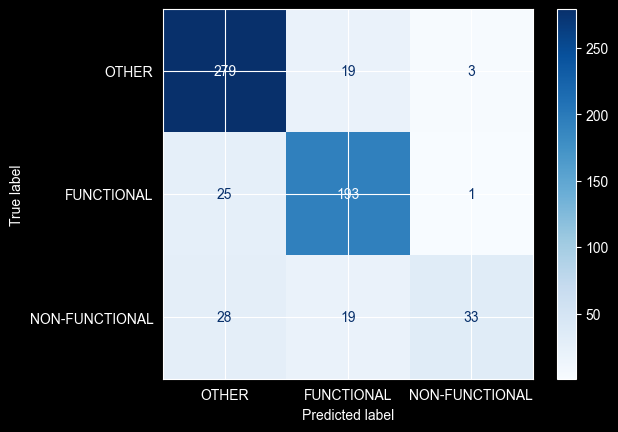

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay.from_estimator(
    pipe,
    X_test,
    y_test,
    display_labels=y_levels,
    cmap='Blues'
)

### Matrica konfuzije (Confusion Matrix)

Za detaljnu evaluaciju performansi ovog pipeline-a iskoriscena je matrica konfuzije dobijena pomocu funkcije `ConfusionMatrixDisplay.from_estimator`.

Prikazane vrednosti na **glavnoj dijagonali** oznacavaju tacna predvidjanja modela (True Positives), dok ostale celije pokazuju greske u klasifikaciji.

**Zakljucak:**
* **Klasa OTHER:** model najpreciznije prepoznaje ovu klasu. Uspesno je klasifikovao **279 recenzija**, dok je napravio minimalan broj gresaka (19 je pogresno svrstao u *Functional*, a samo 3 u *Non-Functional*).
* **Klasa FUNCTIONAL:** model pokazuje visoku uspesnost sa **193 tacno prepoznate recenzije**. Glavni izvor greske je mesanje sa klasom *OTHER* (25 recenzija), sto je ocekivano zbog kompleksnosti recnika i stilske slicnosti u tekstu recenzija.
* **Problem disbalansa klasa:** matrica potvrdjuje da model, uprkos izrazenom *class imbalance* problemu koji je uocen na pocetku, nije postao "lenj" baseline model (koji bi sve predvidjao kao *OTHER*).
Naprotiv, stablo odlucivanja uspesno pronalazi obrasce i visoko je selektivno za sve tri kategorije.

In [26]:
prediction = pipe.predict(X_test)

report= metrics.classification_report(y_true=y_test, y_pred=prediction)
print(report)

              precision    recall  f1-score   support

           0       0.84      0.93      0.88       301
           1       0.84      0.88      0.86       219
           2       0.89      0.41      0.56        80

    accuracy                           0.84       600
   macro avg       0.86      0.74      0.77       600
weighted avg       0.85      0.84      0.83       600



- **support** - ukupan broj pojavljivanja stvarnih uzoraka svake klase u y_true - u test skupu (npr. u test skupu ima tacno 301 recenzija koja je stvarno 'OTHER')


- **macro avg** - prosek rezultata po klasama, pri cemu svaka klasa ima jednaku tezinu, nezavisno od broja njenih uzoraka i zbog toga los rezultat na manjinskoj ili tezoj klasi znacajno utice na konacnu vrednost proseka


- **weighted avg** - racuna prosek tako sto uzima u obzir broj primeraka (support) svake klase; klase koje imaju vise uzoraka u data setu imaju i veci uticaj na krajnji rezultat; koristan je kada nam je bitna ukupna tacnost na celom (nebalansiranom) skupu

#### BALANCED ACCURACY

S obzirom da smo vec utvrdili da dataset nije balansiran (podsetimo se da je vise od 50% rezencija klase OTHER), racunacemo i **balanced accuracy**.

Balanced accuracy se racuna kao zbir accuracy po klasama podeljen sa ukupnim brojem testnih uzoraka.

Koristimo ga kada zelimo da obezbedimo da model ne postize visok ukupni rezultat, a da pri tome lose klasifikuje manjinsku klasu (realno prikazuje uspeh ako jedna klasa ima znatno manje primeraka od druge).

In [28]:
display(f"Accuracy: {metrics.accuracy_score(y_test, prediction):0.4f}")
display(f"Balanced accuracy: {metrics.balanced_accuracy_score(y_test, prediction, adjusted=True):0.4f}")

'Accuracy: 0.8417'

'Balanced accuracy: 0.6103'

- **slucajni model** - model koji nema nikakvo znanje i samo nasumicno bira klasu


- `adjusted=True` - postavlja njegov rezultat kao 0 kako bi se lakse procenilo koliko je nas model bolji od slucajnog pogadjanja


- sve sto model uradi iznad nule je njegovo stvarno znanje, dok bi negativan rezultat znacio da radi gore od slucajnog pogadjanja